# **libraries**

In [ ]:
!pip install -q transformers datasets evaluate accelerate bitsandbytes matplotlib peft

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.1/76.1 MB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 63.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import torch
import time
import matplotlib.pyplot as plt
import numpy as np
import re
import gc
from transformers import (
    AutoTokenizer, AutoModelForCausalLM,
    TrainingArguments, Trainer,
    DataCollatorForLanguageModeling
)
from datasets import load_dataset
import evaluate
from peft import LoraConfig, get_peft_model
from IPython.display import display, HTML
import pandas as pd

# **Check for available hardware**

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(torch.cuda.get_device_properties(0).total_memory/1e9, 2), "GB")
else:
    print("WARNING: No GPU detected. This notebook will run very slowly on CPU.")

Using device: cuda
GPU: Tesla T4
GPU Memory: 15.83 GB


# **Load Model and Datasets**

In [ ]:
model_name = "tiiuae/falcon-rw-1b"

In [ ]:
# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True, padding_side="left")
tokenizer.pad_token = tokenizer.eos_token

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/234 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

In [ ]:
# Load base model
model = AutoModelForCausalLM.from_pretrained(model_name, trust_remote_code=True).to(device)

config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

configuration_falcon.py:   0%|          | 0.00/6.70k [00:00<?, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/tiiuae/falcon-rw-1b:
- configuration_falcon.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_falcon.py:   0%|          | 0.00/56.9k [00:00<?, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/tiiuae/falcon-rw-1b:
- modeling_falcon.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin:   0%|          | 0.00/2.62G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.62G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/115 [00:00<?, ?B/s]

In [ ]:
# Load datasets
wikitext = load_dataset("wikitext", "wikitext-2-raw-v1", split="test[:100]")
gsm8k = load_dataset("gsm8k", "main", split="test[:100]")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/733k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/6.36M [00:00<?, ?B/s]

validation-00000-of-00001.parquet:   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

...

README.md:   0%|          | 0.00/7.94k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

# Evaluation

In [ ]:
def extract_answer(text):
    """Extract numerical answer from GSM8K problems"""
    match = re.search(r"####\s*(-?\d+)", text)
    return match.group(1) if match else None

In [ ]:
def evaluate_gsm8k_metrics(model, dataset, use_amp=False):
    """Evaluate model accuracy on GSM8K dataset"""
    model.eval()
    preds, labels = [], []

    with torch.no_grad():
        for example in dataset:
            question = example["question"]
            label = extract_answer(example["answer"])
            if not label:
                continue

            enc = tokenizer(question, return_tensors="pt", truncation=True, padding=True, max_length=64).to(device)

            if use_amp and torch.cuda.is_available():
                with torch.amp.autocast(device_type=device, dtype=torch.float16):
                    output = model.generate(**enc, max_new_tokens=64)
            else:
                output = model.generate(**enc, max_new_tokens=64)

            prediction = tokenizer.decode(output[0], skip_special_tokens=True)
            pred_number = re.search(r"(-?\d+)", prediction)
            pred = pred_number.group(1) if pred_number else "NaN"

            preds.append(pred)
            labels.append(label)

    # Clean numeric predictions
    valid = [(p, l) for p, l in zip(preds, labels) if p.isdigit() and l.isdigit()]
    if not valid:
        return {"accuracy": 0, "precision": 0, "recall": 0}

    pred_list, label_list = zip(*[(int(p), int(l)) for p, l in valid])

    accuracy_metric = evaluate.load("accuracy")
    precision_metric = evaluate.load("precision")
    recall_metric = evaluate.load("recall")

    acc = accuracy_metric.compute(predictions=pred_list, references=label_list)
    prec = precision_metric.compute(predictions=pred_list, references=label_list, average="macro")
    rec = recall_metric.compute(predictions=pred_list, references=label_list, average="macro")

    return {
        "accuracy": acc["accuracy"],
        "precision": prec["precision"],
        "recall": rec["recall"]
    }

# **Benchmark Functions**

## **Base benchmark**

In [ ]:
def benchmark(model, dataset, task='language_modeling', max_length=64):
    """Benchmark model throughput on a dataset"""
    model.eval()
    total_tokens, total_time = 0, 0.0

    with torch.no_grad():
        for ex in dataset:
            text = ex["text"] if task == "language_modeling" else ex["question"]
            enc = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=max_length)
            enc = {k: v.to(device).long() for k, v in enc.items()}
            tokens = enc["input_ids"].numel()

            torch.cuda.synchronize() if torch.cuda.is_available() else None
            start = time.perf_counter()
            _ = model(**enc)
            torch.cuda.synchronize() if torch.cuda.is_available() else None
            end = time.perf_counter()

            total_tokens += tokens
            total_time += (end - start)

    return total_tokens / total_time

## **Optimize benchmark**

In [ ]:
def benchmark_fp16(model, dataset, task="language_modeling", max_length=64):
    """Benchmark model throughput using FP16 mixed precision"""
    model.eval()
    total_tokens, total_time = 0, 0.0

    with torch.no_grad():
        for ex in dataset:
            txt = ex["text"] if task == "language_modeling" else ex["question"]
            enc = tokenizer(txt, return_tensors="pt", truncation=True, padding=True, max_length=max_length)
            input_ids = enc["input_ids"].to(device).long()
            attention_mask = enc["attention_mask"].to(device).long()
            n_tok = input_ids.numel()

            torch.cuda.synchronize() if torch.cuda.is_available() else None
            t0 = time.perf_counter()
            with torch.amp.autocast(device_type=device, dtype=torch.float16):
                _ = model(input_ids=input_ids, attention_mask=attention_mask)
            torch.cuda.synchronize() if torch.cuda.is_available() else None
            total_time += time.perf_counter() - t0
            total_tokens += n_tok

    return total_tokens / total_time

# **Fine-tune the model with LoRA**

In [ ]:
model_optimized = AutoModelForCausalLM.from_pretrained(model_name, trust_remote_code=True).to(device)

In [ ]:
# Prepare training data
small_train = load_dataset("wikitext", "wikitext-2-raw-v1", split="train[:500]")

def tokenize_function(example):
    return tokenizer(example["text"], truncation=True, padding="max_length", max_length=64)

tokenized_train = small_train.map(tokenize_function, batched=True)
tokenized_train.set_format(type="torch", columns=["input_ids", "attention_mask"])

# Configure LoRA adaptation
print("Configuring LoRA for efficient fine-tuning...")
peft_config = LoraConfig(
    r=16,                  # Rank of the update matrices
    lora_alpha=32,         # Scaling factor
    lora_dropout=0.05,     # Dropout probability
    bias="none",           # Don't adapt bias
    task_type="CAUSAL_LM", # Task type
    target_modules=["query_key_value"]  # Modules to target with LoRA
)

# Apply LoRA to the model
model_lora = get_peft_model(model_optimized, peft_config)
print(f"Trainable parameters: {model_lora.print_trainable_parameters()}")

# Configure training
model_lora.config.use_cache = False
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

training_args = TrainingArguments(
    output_dir="./results",
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    fp16=True,
    logging_steps=20,
    learning_rate=3e-4,
    warmup_steps=50,
    save_strategy="no",
    report_to="none"
)

trainer = Trainer(
    model=model_lora,
    args=training_args,
    train_dataset=tokenized_train,
    tokenizer=tokenizer,
    data_collator=data_collator
)

print("Fine-tuning model...")
trainer.train()

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Configuring LoRA for efficient fine-tuning...


<ipython-input-13-228e0caa4de1>:42: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


trainable params: 3,145,728 || all params: 1,314,770,944 || trainable%: 0.2393
Trainable parameters: None
Fine-tuning model...


Step,Training Loss
20,4.751800


TrainOutput(global_step=31, training_loss=4.420224835795741, metrics={'train_runtime': 18.124, 'train_samples_per_second': 27.588, 'train_steps_per_second': 1.71, 'total_flos': 230794438115328.0, 'train_loss': 4.420224835795741, 'epoch': 0.992})

# **Benchmark results**

## **base model**

In [ ]:
print("Benchmarking base model on WikiText...")
throughput_base_wiki = benchmark(model, wikitext, task="language_modeling")
print(f"WikiText: {throughput_base_wiki:.2f} tokens/sec")

print("Benchmarking base model on GSM8K...")
throughput_base_gsm8k = benchmark(model, gsm8k, task="question_answering")
print(f"GSM8K: {throughput_base_gsm8k:.2f} tokens/sec")

print("Evaluating base model accuracy on GSM8K...")
metrics_base = evaluate_gsm8k_metrics(model, gsm8k)
print(f"Base model GSM8K metrics: {metrics_base}")

Benchmarking base model on WikiText...
WikiText: 742.95 tokens/sec
Benchmarking base model on GSM8K...


Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


GSM8K: 787.11 tokens/sec
Evaluating base model accuracy on GSM8K...


Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for o

Base model GSM8K metrics: {'accuracy': 0.030927835051546393, 'precision': 0.007254901960784314, 'recall': 0.02745098039215686}


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## **optimized model**

In [ ]:
print("Creating optimized model with FP16 mixed precision...")
# We'll create a fresh model instance for fair comparison
del model
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

model_optimized = AutoModelForCausalLM.from_pretrained(model_name, trust_remote_code=True).to(device)

Creating optimized model with FP16 mixed precision...


In [ ]:
print("Benchmarking optimized model (AMP FP16)...")
throughput_fp16_wiki = benchmark_fp16(model_optimized, wikitext, task="language_modeling")
print(f"WikiText (FP16): {throughput_fp16_wiki:.2f} tokens/sec")

throughput_fp16_gsm8k = benchmark_fp16(model_optimized, gsm8k, task="question_answering")
print(f"GSM8K (FP16): {throughput_fp16_gsm8k:.2f} tokens/sec")

print("Evaluating optimized model accuracy on GSM8K...")
metrics_optimized = evaluate_gsm8k_metrics(model_optimized, gsm8k, use_amp=True)
print(f"Optimized model GSM8K metrics: {metrics_optimized}")

Benchmarking optimized model (AMP FP16)...
WikiText (FP16): 631.60 tokens/sec


Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


GSM8K (FP16): 977.73 tokens/sec
Evaluating optimized model accuracy on GSM8K...


Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for o

Optimized model GSM8K metrics: {'accuracy': 0.030927835051546393, 'precision': 0.007254901960784314, 'recall': 0.02745098039215686}


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## **fine-tuned model**

In [ ]:
print("Benchmarking fine-tuned model...")
throughput_finetuned_wiki = benchmark(model_lora, wikitext)
print(f"WikiText (Fine-tuned): {throughput_finetuned_wiki:.2f} tokens/sec")

throughput_finetuned_gsm8k = benchmark(model_lora, gsm8k, task="question_answering")
print(f"GSM8K (Fine-tuned): {throughput_finetuned_gsm8k:.2f} tokens/sec")

print("Evaluating fine-tuned model accuracy on GSM8K...")
metrics_finetuned = evaluate_gsm8k_metrics(model_lora, gsm8k)
print(f"Fine-tuned model GSM8K metrics: {metrics_finetuned}")

Benchmarking fine-tuned model...
WikiText (Fine-tuned): 622.35 tokens/sec


Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


GSM8K (Fine-tuned): 937.74 tokens/sec
Evaluating fine-tuned model accuracy on GSM8K...


Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2 for o

Fine-tuned model GSM8K metrics: {'accuracy': 0.030927835051546393, 'precision': 0.007254901960784314, 'recall': 0.02745098039215686}


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# **Visualize Results**

In [ ]:
# Throughput comparison
labels = ["Base", "Optimized (FP16)", "Fine-tuned (LoRA)"]
wiki_vals = [throughput_base_wiki, throughput_fp16_wiki, throughput_finetuned_wiki]
gsm_vals = [throughput_base_gsm8k, throughput_fp16_gsm8k, throughput_finetuned_gsm8k]

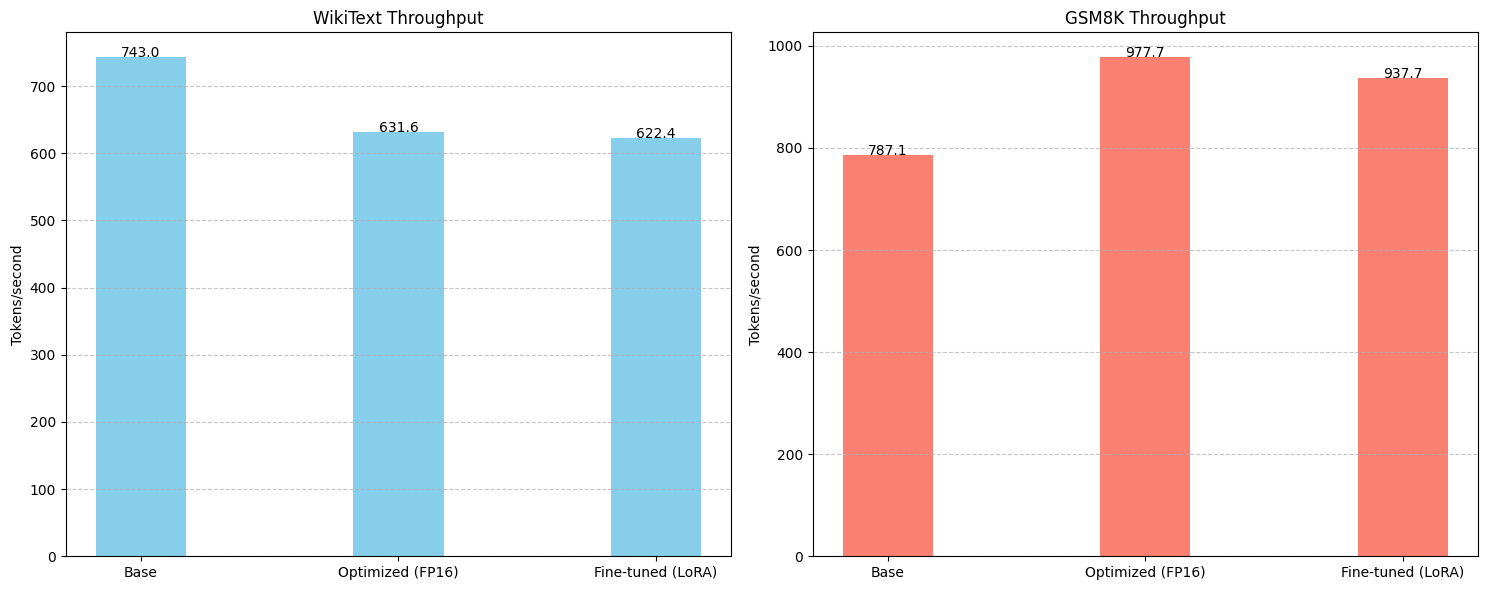

In [ ]:
# Plot throughput
x = np.arange(len(labels))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.bar(x, wiki_vals, width, color='skyblue')
ax1.set_ylabel('Tokens/second')
ax1.set_title('WikiText Throughput')
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for i, v in enumerate(wiki_vals):
    ax1.text(i, v + 0.1, f"{v:.1f}", ha='center')

ax2.bar(x, gsm_vals, width, color='salmon')
ax2.set_ylabel('Tokens/second')
ax2.set_title('GSM8K Throughput')
ax2.set_xticks(x)
ax2.set_xticklabels(labels)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

for i, v in enumerate(gsm_vals):
    ax2.text(i, v + 0.1, f"{v:.1f}", ha='center')

plt.tight_layout()
plt.savefig('throughput_comparison.png')
plt.show()

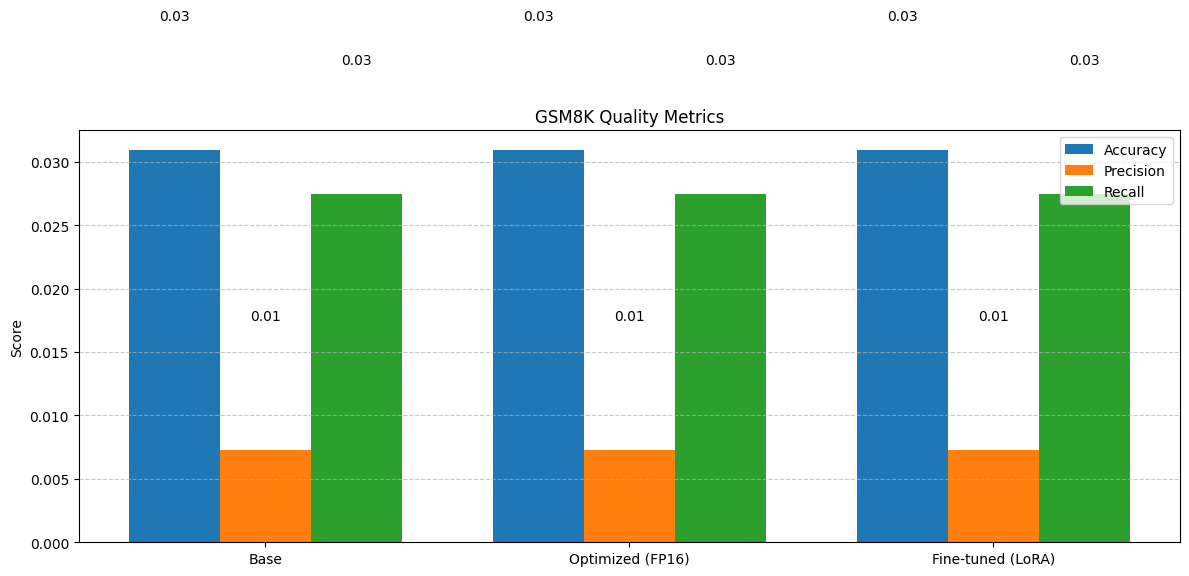

In [ ]:
# Accuracy comparison
metrics_list = [metrics_base, metrics_optimized, metrics_finetuned]
metric_names = ['Accuracy', 'Precision', 'Recall']
metrics_values = {
    'Accuracy': [m['accuracy'] for m in metrics_list],
    'Precision': [m['precision'] for m in metrics_list],
    'Recall': [m['recall'] for m in metrics_list]
}

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
bars = []

for i, metric in enumerate(metric_names):
    offset = width * (i - 1)
    bar = ax.bar(x + offset, metrics_values[metric], width, label=metric)
    bars.append(bar)

ax.set_ylabel('Score')
ax.set_title('GSM8K Quality Metrics')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add values on bars
for bar in bars:
    for rect in bar:
        height = rect.get_height()
        ax.text(rect.get_x() + rect.get_width()/2., height + 0.01,
                f'{height:.2f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig('quality_comparison.png')
plt.show()

# **Summary**

In [ ]:
# Create summary table
throughput_data = {
    'Model Version': labels,
    'WikiText (tokens/sec)': wiki_vals,
    'GSM8K (tokens/sec)': gsm_vals,
    'Accuracy': metrics_values['Accuracy'],
    'Precision': metrics_values['Precision'],
    'Recall': metrics_values['Recall']
}

summary_df = pd.DataFrame(throughput_data)
display(summary_df)

,Model Version,WikiText (tokens/sec),GSM8K (tokens/sec),Accuracy,Precision,Recall
0,Base,742.950692,787.110037,0.030928,0.007255,0.027451
1,Optimized (FP16),631.602860,977.731907,0.030928,0.007255,0.027451
2,Fine-tuned (LoRA),622.352027,937.735766,0.030928,0.007255,0.027451


In [ ]:
# Calculate improvements
wiki_speedup = [(throughput_fp16_wiki/throughput_base_wiki - 1) * 100,
                (throughput_finetuned_wiki/throughput_base_wiki - 1) * 100]
gsm_speedup = [(throughput_fp16_gsm8k/throughput_base_gsm8k - 1) * 100,
               (throughput_finetuned_gsm8k/throughput_base_gsm8k - 1) * 100]

print("\nThroughput improvements:")
print(f"WikiText: FP16 optimization: {wiki_speedup[0]:.1f}%, LoRA fine-tuning: {wiki_speedup[1]:.1f}%")
print(f"GSM8K: FP16 optimization: {gsm_speedup[0]:.1f}%, LoRA fine-tuning: {gsm_speedup[1]:.1f}%")

print("\nQuality improvements (on GSM8K):")
accuracy_improvements = [(metrics_optimized['accuracy']/metrics_base['accuracy'] - 1) * 100 if metrics_base['accuracy'] > 0 else 0,
                        (metrics_finetuned['accuracy']/metrics_base['accuracy'] - 1) * 100 if metrics_base['accuracy'] > 0 else 0]
print(f"Accuracy: FP16 optimization: {accuracy_improvements[0]:.1f}%, LoRA fine-tuning: {accuracy_improvements[1]:.1f}%")



Throughput improvements:
WikiText: FP16 optimization: -15.0%, LoRA fine-tuning: -16.2%
GSM8K: FP16 optimization: 24.2%, LoRA fine-tuning: 19.1%

Quality improvements (on GSM8K):
Accuracy: FP16 optimization: 0.0%, LoRA fine-tuning: 0.0%
